In [70]:
import os
from pathlib import Path

import yaml
import pickle

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
from sklearn.manifold import TSNE
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_selection import r_regression
from seaborn import heatmap

if Path.cwd().name == 'notebooks':
    os.chdir("..")
from src.dl_permutations.models.rnn_encoder import RNNEncoder
from src.dl_permutations.genetic_alg.lon import generate_local_optima_network
from src.dl_permutations.genetic_alg.tsp import TSP
from src.dl_permutations.genetic_alg.ga import GA_TSP

In [2]:
ROOT_PATH = os.getcwd()

TRAJECTORIES_PATH = os.path.join(ROOT_PATH, 'outputs', 'trajectories.npz')
MODEL_PATH = os.path.join(ROOT_PATH, 'outputs', 'contrastive_encoder.pt')
MODEL_CONFIG_PATH = os.path.join(ROOT_PATH, 'src', 'dl_permutations', 'contrastive_trajectory_config.yaml')

## Load data

In [3]:
config = yaml.safe_load(open(MODEL_CONFIG_PATH))
model_config = config['model_config']
tsp_config = config['tsp_config']
ga_config= config['ga_config']

In [4]:
encoder = RNNEncoder(config['tsp_config']['cities_count'],
                     model_config['emb_dim'],
                     model_config['hidden_size'],
                     model_config['out_dim'],
                     model_config['dropout'],
                     model_config['normalize'])
encoder.load_state_dict(torch.load(MODEL_PATH, weights_only=True, map_location=torch.device('cpu')))

<All keys matched successfully>

In [5]:
trajectories = np.load(TRAJECTORIES_PATH)
trajectories_df = pd.DataFrame({
    'run_id': trajectories['run_id'],
    'generation': trajectories['generation'],
    'perm': tuple(trajectories['perm']),
    'fitness': trajectories['fitness'],
})
trajectories_df.head()

,run_id,generation,perm,fitness
0,0,0,"[11, 9, 16, 10, 8, 7, 13, 6, 1, 4, 14, 2, 15, ...",88.069287
1,0,1,"[16, 9, 4, 10, 17, 12, 8, 5, 11, 18, 1, 13, 19...",79.176408
2,0,2,"[16, 9, 4, 10, 17, 12, 8, 5, 11, 18, 1, 13, 19...",79.176408
3,0,3,"[2, 6, 13, 4, 14, 18, 1, 9, 8, 11, 5, 3, 7, 12...",70.807971
4,0,4,"[2, 6, 13, 4, 14, 18, 1, 9, 8, 11, 5, 3, 7, 12...",70.807971


In [6]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
encoder = encoder.to(device)
embeddings = encoder(torch.tensor(trajectories['perm']).to(device)).detach().cpu().numpy()
embeddings.shape

(10000, 64)

## Basic plots

In [7]:
run_ids = np.random.choice(trajectories_df['run_id'].unique(), size=20, replace=False)
row_ids = trajectories_df[trajectories_df['run_id'].isin(run_ids)].index

tsne = TSNE(n_components=2, perplexity=30, random_state=42, max_iter=1000)
X_tsne = tsne.fit_transform(embeddings[row_ids])

In [8]:
fig = go.Figure(data=go.Scatter(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    mode='markers',
    marker=dict(
        color=trajectories_df['run_id'].values[row_ids],
        colorscale='jet',
        size=5,
    ),
    hovertemplate='run_id: %{marker.color}<br>generation: %{customdata}<extra></extra>',
    customdata=trajectories_df['generation'].values[row_ids],
))
fig.update_layout(
    {
        'title': 'TSNE of path embeddings, colored by run id',
        'xaxis_title': 't-SNE 1',
        'yaxis_title': 't-SNE 2',
    }
)
fig.show()

In [9]:
fig = go.Figure(data=go.Scatter(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    mode='markers',
    marker=dict(
        color=trajectories_df['generation'].values[row_ids],
        colorscale='viridis',
        size=5,
    ),
    hovertemplate='run_id: %{marker.color}<br>generation: %{customdata}<extra></extra>',
    customdata=trajectories_df['generation'].values[row_ids],
))
fig.update_layout(
    {
        'title': 'TSNE of path embeddings, colored by generation',
        'xaxis_title': 't-SNE 1',
        'yaxis_title': 't-SNE 2',
    }
)
fig.show()

## Finding optima

In [10]:
trajectories_df.dtypes

run_id          int64
generation      int64
perm           object
fitness       float64
dtype: object

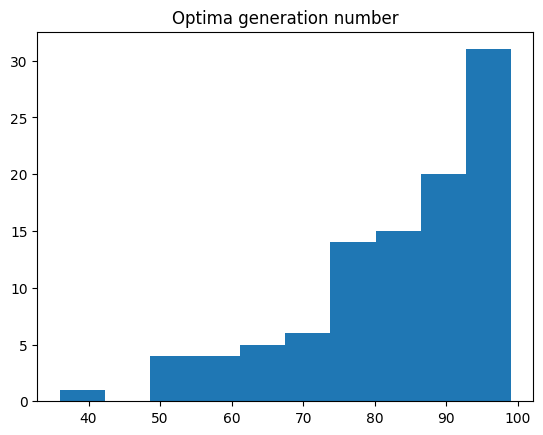

In [11]:
optima_rows = trajectories_df.groupby('run_id')['fitness'].idxmin().values
plt.hist(trajectories_df['generation'].values[optima_rows])
plt.title('Optima generation number')
plt.show()

In [12]:
optima = trajectories_df.loc[optima_rows, 'perm']
optima = [t for t in optima.apply(tuple).unique()]
print("Number of unique optima: ", len(optima))

Number of unique optima:  99


## Making LON

In [13]:
tsp_instance = TSP(cities_count=tsp_config['cities_count'],
                   min=tsp_config['min'],
                   max=tsp_config['max'],
                   start=tsp_config['start'],
                   seed=tsp_config['seed'])

ga_kwargs = {'cities':tsp_instance.cities,
            'population_size':ga_config['population_size'],
            'mutation_rate':ga_config['mutation_rate'],
            'cross_rate':ga_config['cross_rate'],
            'tournament_size':ga_config['tournament_size'],
            'fitness': tsp_instance.total_distance}

lon_epochs = int(ga_config['n_generations']/10)
samples_per_node = 100

In [14]:
with open(f'outputs/lon_e{lon_epochs}_spn{samples_per_node}.pkl', 'rb') as f:
    lon = pickle.load(f)

In [15]:
lon.number_of_edges()

111

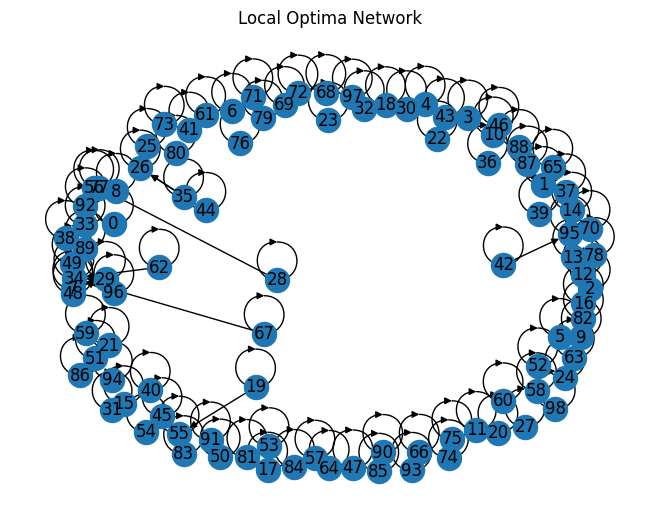

In [16]:
nx.draw(lon, with_labels=True)
plt.title('Local Optima Network')
plt.show()

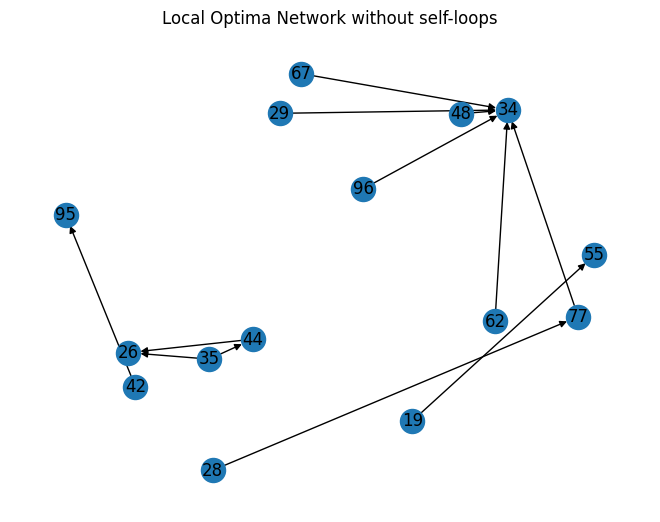

In [17]:
lon.remove_edges_from(nx.selfloop_edges(lon))
lon.remove_nodes_from(list(nx.isolates(lon)))
nx.draw(lon, with_labels=True)
plt.title('Local Optima Network without self-loops')
plt.show()

In [80]:
lon_perms = trajectories_df.loc[optima_rows].reset_index().loc[list(lon.nodes)]
lon_perms

,index,run_id,generation,perm,fitness
19,1985,19,85,"[2, 1, 16, 13, 18, 9, 19, 17, 12, 8, 7, 11, 5,...",44.198316
26,2689,26,89,"[13, 16, 1, 18, 9, 19, 17, 12, 8, 7, 10, 11, 5...",41.979213
28,2894,28,94,"[6, 15, 4, 3, 10, 11, 5, 7, 17, 12, 8, 19, 9, ...",45.241251
29,2983,29,83,"[15, 4, 3, 5, 11, 10, 8, 12, 17, 19, 7, 9, 18,...",45.660067
34,3486,34,86,"[15, 4, 3, 5, 11, 10, 7, 8, 12, 17, 19, 9, 18,...",41.049378
35,3591,35,91,"[13, 16, 1, 18, 9, 19, 17, 12, 8, 7, 10, 5, 11...",42.569424
42,4299,42,99,"[6, 2, 14, 15, 4, 3, 10, 5, 11, 7, 19, 17, 12,...",44.727786
44,4487,44,87,"[13, 16, 1, 18, 9, 19, 17, 12, 8, 7, 11, 5, 10...",42.331746
48,4889,48,89,"[5, 11, 19, 12, 17, 8, 7, 10, 4, 3, 15, 9, 18,...",47.325209
55,5570,55,70,"[6, 2, 5, 11, 3, 10, 19, 9, 16, 13, 1, 18, 17,...",50.179962


In [82]:
for edge in lon.edges():
    print(f"edge: {edge}, weight: {lon.edges[edge]['weight']}, fitness diff: {lon_perms.loc[edge[0], 'fitness'] - lon_perms.loc[edge[1], 'fitness']}")

edge: (19, 55), weight: 0.03, fitness diff: -5.9816450990088725
edge: (28, 77), weight: 0.01, fitness diff: -8.199377293229496
edge: (29, 34), weight: 0.03, fitness diff: 4.610688848495258
edge: (35, 44), weight: 0.23, fitness diff: 0.23767746295416003
edge: (35, 26), weight: 0.31, fitness diff: 0.5902109400084825
edge: (42, 95), weight: 0.03, fitness diff: -11.254088524972012
edge: (44, 26), weight: 0.1, fitness diff: 0.3525334770543225
edge: (48, 34), weight: 0.42, fitness diff: 6.275830973996349
edge: (62, 34), weight: 0.02, fitness diff: 7.911251237310886
edge: (67, 34), weight: 0.01, fitness diff: 7.602013132314653
edge: (77, 34), weight: 0.01, fitness diff: 12.391249737908936
edge: (96, 34), weight: 0.08, fitness diff: 1.282368053745536


## LON analysis

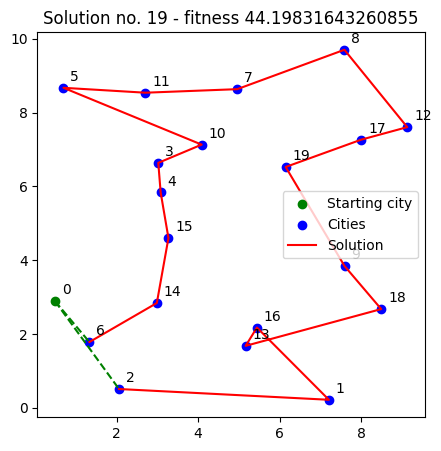

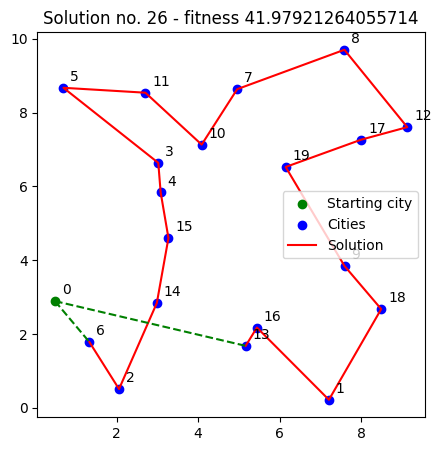

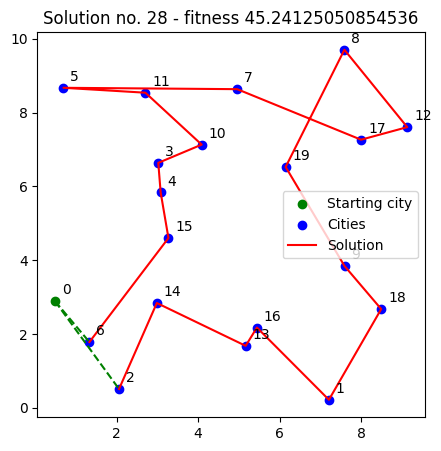

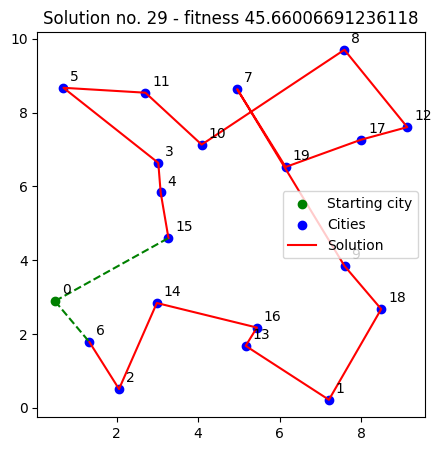

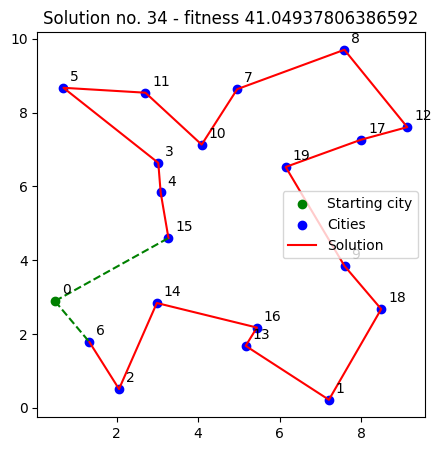

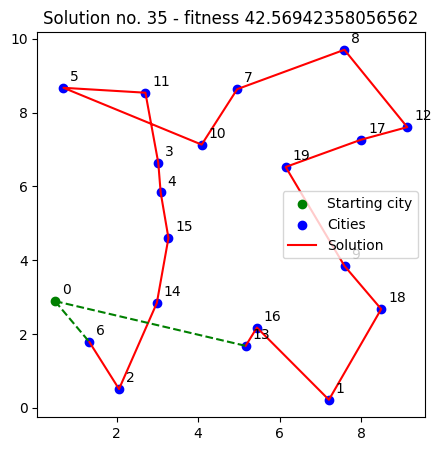

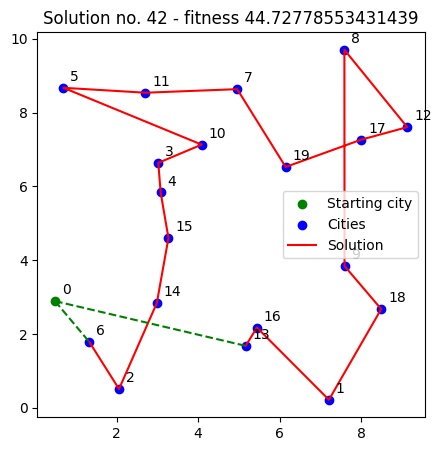

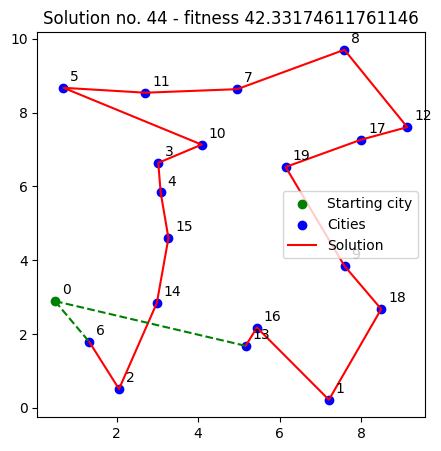

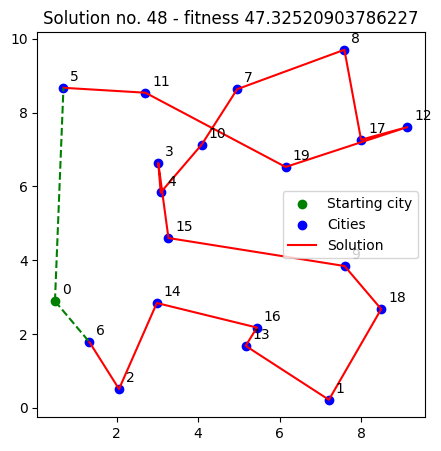

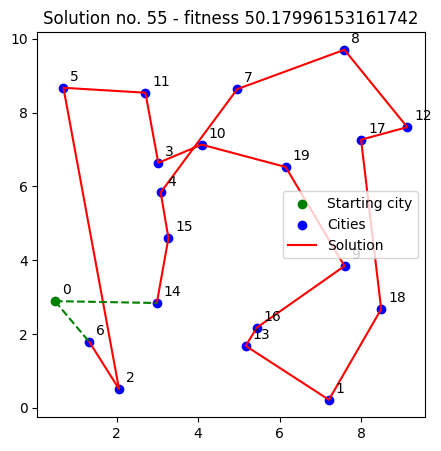

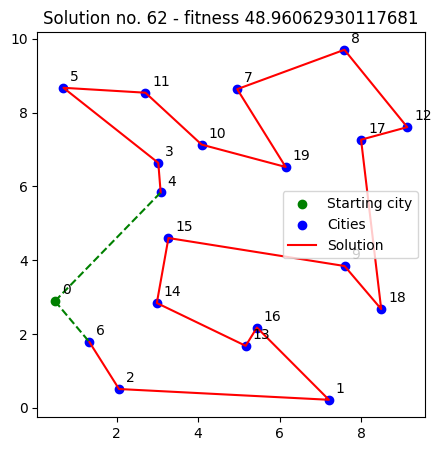

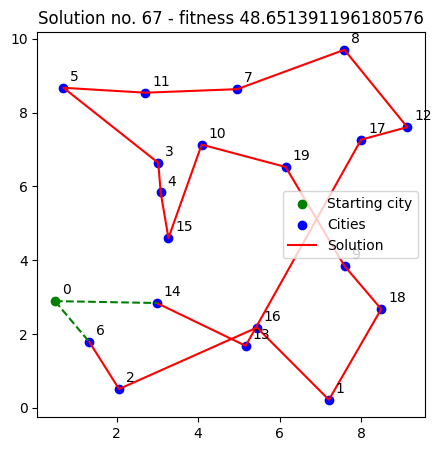

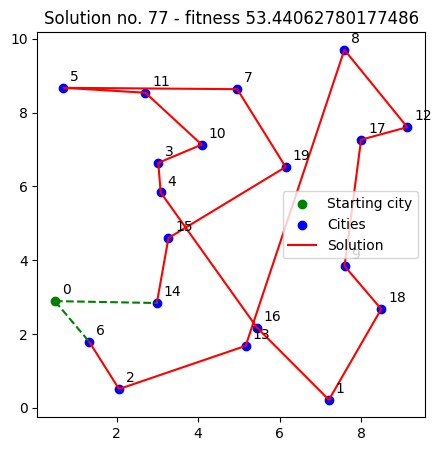

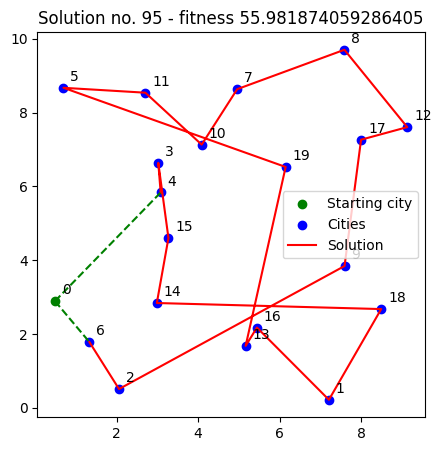

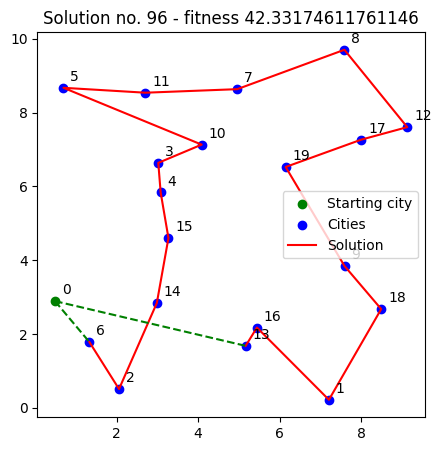

In [69]:
for row in lon_perms.itertuples():
    tsp_instance.plot_solution(row.perm, 
                               figsize=(5,5),
                               title=f"Solution no. {row[0]} - fitness {row.fitness}")

In [57]:
lon_emb_sim = dict()
for edge in lon.edges():
    sim = cosine_similarity(
                        embeddings[lon_perms[lon_perms.index==edge[0]]['index']],
                        embeddings[lon_perms[lon_perms.index==edge[1]]['index']])[0]
    lon_emb_sim[edge] = sim
    print(f"Edge {edge} embeddings sim: {sim}")

Edge (19, 55) embeddings sim: [0.44821924]
Edge (28, 77) embeddings sim: [0.00343876]
Edge (29, 34) embeddings sim: [0.9869374]
Edge (35, 44) embeddings sim: [0.8856359]
Edge (35, 26) embeddings sim: [0.9409463]
Edge (42, 95) embeddings sim: [0.08177753]
Edge (44, 26) embeddings sim: [0.9249827]
Edge (48, 34) embeddings sim: [0.3187548]
Edge (62, 34) embeddings sim: [-0.5211654]
Edge (67, 34) embeddings sim: [-0.06975815]
Edge (77, 34) embeddings sim: [-0.01109231]
Edge (96, 34) embeddings sim: [-0.06095662]


In [59]:
print("Pearson correlation between edge probabilities and cosine similarity:\n",
      r_regression(list(lon_emb_sim.values()), [lon.edges[e]['weight'] for e in lon.edges]))

Pearson correlation between edge probabilities and cosine similarity:
 [0.4344028]


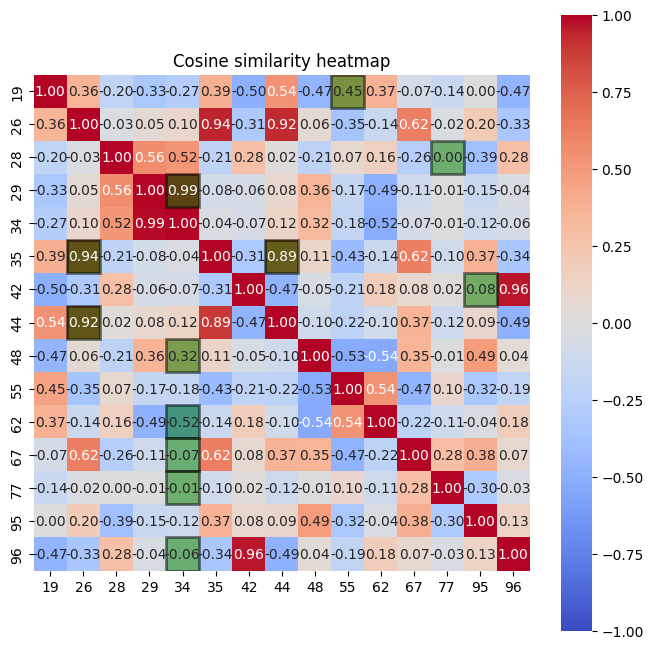

In [ ]:
fig, ax = plt.subplots(figsize=(8,8))
heatmap(
    cosine_similarity(embeddings[lon_perms['index']]),
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1, vmax=1,
    square=True,
    xticklabels=lon_perms.index,
    yticklabels=lon_perms.index,
    ax=ax
)
idx_map  = {e : i for i, e in enumerate(lon_perms.index)}
for r, c in lon.edges:
    rect = patches.Rectangle(
        (idx_map[c], idx_map[r]), 1, 1, 
        fill=True, 
        facecolor='green', 
        edgecolor='black', 
        linewidth=2, 
        alpha=0.5
    )
    ax.add_patch(rect)

plt.title("Cosine similarity heatmap")
plt.show()